# 00 · Welcome to py-spinnaker2

This is the first notebook in a hands-on series that takes you from your very first
spiking neuron all the way to writing your own custom neuron models for the
SpiNNaker2 neuromorphic chip.

**By the end of this notebook you will:**

- understand the four building blocks of every py-spinnaker2 simulation,
- run your first spiking neural network (SNN) — *with or without* a SpiNNaker2 board,
- and see something a little flashier: a **synfire chain**, a wave of synchronized
  activity rippling through a network.


## 1. SpiNNaker2 & py-spinnaker2

**SpiNNaker2** is a digital neuromorphic many-core system. A single chip contains
152 ARM processing elements (PEs) that simulate neurons in parallel and
exchange *spikes* as tiny network packets — much like biological neurons fire and
communicate. Boards range from a single chip up to 48-chip boards.

**py-spinnaker2** is the lightweight Python interface to that system. You describe a
network in Python; py-spinnaker2 partitions it, maps it onto the hardware, runs the
simulation, and hands the results back to you as plain Python dictionaries and NumPy
arrays. The API is inspired by [PyNN](http://neuralensemble.org/PyNN/).

We will introduce the hardware itself in depth in [06 · Hardware architecture](./06_hardware_architecture.ipynb). For now, treat it
as a fast parallel simulator of spiking neurons.


## 2. Setup

If you have not installed py-spinnaker2 yet, follow the steps below:

```bash
git clone --recursive git@gitlab.com:spinnaker2/py-spinnaker2.git
cd py-spinnaker2/
bash libs_install.sh        # needs sudo; ask your admin if you don't have it
pip install .
```

> **Info**
>
> Running the `libs_install.sh` script should only be required if you are working on a self-managed system. If you are accessing SpiNNaker through an institution, then most likely all dependencies will already be installed in your environment and you won't need this step.


Let's confirm the import works:

In [1]:
# The SNN API, a couple of helpers, and the Brian2 simulation backend.

from spinnaker2 import snn, helpers, brian2_sim
import numpy as np
import matplotlib.pyplot as plt

print("py-spinnaker2 is importable ✔")

py-spinnaker2 is importable ✔


> **Note**
>
> Please see the project [README](https://gitlab.com/spinnaker2/py-spinnaker2/-/blob/main/README.md) and the
> [Quick Start docs](https://spinnaker2.gitlab.io/py-spinnaker2) for the full guide.

## 3. Where to run: hardware or simulator

The Brian2 backend and the hardware backends expose the **same** `.run(net, timesteps)` method, so you write your
network once and choose the backend with one variable.

- [`hardware.SpiNNaker2Chip()`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/hardware-api.html#spinnaker2.hardware.SpiNNaker2Chip) — a single-chip board (e.g. SpiNNode)
- [`hardware.SpiNNcloud48NodeBoard()`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/hardware-api.html#spinnaker2.hardware.SpiNNcloud48NodeBoard) — a 48-chip SpiNNcloud board
- [`brian2_sim.Brian2Backend()`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/brian2_sim-api.html#spinnaker2.brian2_sim.Brian2Backend) — pure-software simulator, no board required

(How to pick a *specific* board by name, ethernet IP, or board id is covered in
[04 · Hardware allocation](./04_hardware_allocation.ipynb).)

In [2]:
# Flip this to True once you have a SpiNNaker2 board configured.
USE_HARDWARE = True

if USE_HARDWARE:
    from spinnaker2 import hardware

    hw = hardware.SpiNNcloud48NodeBoard()  # or hardware.SpiNNaker2Chip()
else:
    hw = brian2_sim.Brian2Backend()

print("Running on backend:", type(hw).__name__)

INFO:     Path to spinnaker configuration directory found in global config path /etc/opt/spinnaker/SPINNAKER_CONFIG_PATH


Running on backend: SpiNNcloud48NodeBoard


## 4. The mental model: 4 building blocks

Every py-spinnaker2 simulation is built from the same four objects:

<img src="images/building_blocks.svg" style="max-width:50%;height:auto" alt="The four building blocks">

1. **[`Population`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Population)** — a group of neurons that share a *neuron model* (e.g. [`"lif"`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-lif))
   and a set of *parameters*.
2. **[`Projection`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Projection)** — the synaptic connections from one population to another. Each
   connection is `[pre_index, post_index, weight, delay]`.
3. **[`Network`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Network)** — the container you add populations and projections to.
4. **The backend** (`hw`) — runs the network for a number of time steps.

Let's build one.


## 5. Your first SNN: a single LIF neuron

We'll wire up the smallest network:

- a **stimulus** population of 2 spike sources that fire at fixed, pre-defined times,
- a single **LIF** (Leaky Integrate-and-Fire) neuron that integrates those inputs,
- one **excitatory** and one **inhibitory** synapse connecting them.

### 5.1 Create the stimulus

A [`"spike_list"`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#spike-list-spike_list) population is a set of input neurons that fire at times you choose. You pass those times as the `params` dictionary: each key is a neuron index, each value the list of time steps at which that neuron fires.

In [3]:
input_spikes = {
    0: [1, 4, 9, 11],  # source neuron 0 fires at time steps 1, 4, 9, 11
    1: [20, 30],  # source neuron 1 fires at time steps 20, 30
}
stim = snn.Population(
    size=2,
    neuron_model="spike_list",
    params=input_spikes,
    name="stim",
)

### 5.2 Create the LIF neuron

A LIF neuron accumulates incoming weighted spikes into a membrane voltage `v`. Each
time step the voltage *leaks* toward zero (`v *= alpha_decay`). When `v` crosses the
`threshold`, the neuron emits a spike and resets.

The `reset` global parameter (one setting for the whole population) decides what happens to `v` right after a spike:

- `"reset_by_subtraction"`: subtract the threshold from `v`. If `threshold` is 10 and `v` overshoots to 15 in one step, it becomes 5 (the excess carries over).
- `"reset_to_v_reset"`: reset `v` to a fixed `v_reset` value (e.g. 0), regardless of the overshoot.

We will `record` both the output `spikes` and the full voltage trace `v` so we can
see what's happening inside.

In [4]:
params = {
    "threshold": 10.0,  # fire when v crosses this value
    "alpha_decay": 0.9,  # membrane leak: v *= 0.9 every time step
    "i_offset": 0.0,  # constant background current
    "v_init": 0.0,  # initial membrane voltage
    "v_reset": 0.0,  # voltage to reset to (only for reset_to_v_reset)
    "reset": "reset_by_subtraction",  # or "reset_to_v_reset"
}

pop1 = snn.Population(
    size=1,
    neuron_model="lif",
    params=params,
    name="pop1",
    record=["spikes", "v"],
)

### 5.3 Connect the stimulus to the LIF neuron

Each connection is `[pre_index, post_index, weight, delay]`:

- **weight** is an integer (for `lif`, in the range −15…15). Positive = excitatory,
  negative = inhibitory.
- **delay** is an integer number of time steps. ⚠️ The *effective* delay on hardware is
  always `delay + 1` (a spike takes at least one step to travel between cores).

In [5]:
conns = [
    [0, 0, 10, 0],  # source 0 → neuron 0: excitatory, weight +4, delay 0 + 1
    [1, 0, -3, 1],  # source 1 → neuron 0: inhibitory, weight -3, delay 1 + 1
]
proj = snn.Projection(pre=stim, post=pop1, connections=conns)

### 5.4 Assemble the network and run it

[`net.add(...)`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Network.add) registers each object, giving any unnamed one an automatic name and rejecting duplicate names.

[`hw.run(net, timesteps)`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/brian2_sim-api.html#spinnaker2.brian2_sim.Brian2Backend.run) does everything else: map → configure → run → collect.

In [6]:
snn.Network.clear_names()  # allow re-running this cell (until SpiNNcloud's fix lands)
net = snn.Network("hello_snn")
net.add(stim, pop1, proj)

if USE_HARDWARE: # preliminary fix to be able to rerun hw.run() until SpiNNcloud fixes this
    # A Hardware object allows only one run() — create a fresh one each time this cell runs.
    hw = hardware.SpiNNcloud48NodeBoard()

timesteps = 50
hw.run(net, timesteps)
print("Simulation finished.")

Number of cores needed: 2
Number of available cores: 7104
Sim duration: 0.060000000000000005 s


Recording post-processing duration: 0 s
Simulation finished.


### 5.5 Read the results

Recorded data comes back through the population objects:

- [`pop1.get_spikes()`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/snn-api.html#spinnaker2.snn.Population.get_spikes) → `{neuron_index: [spike_times]}`
- `pop1.get_voltages()` → `{neuron_index: np.array([v per time step])}`

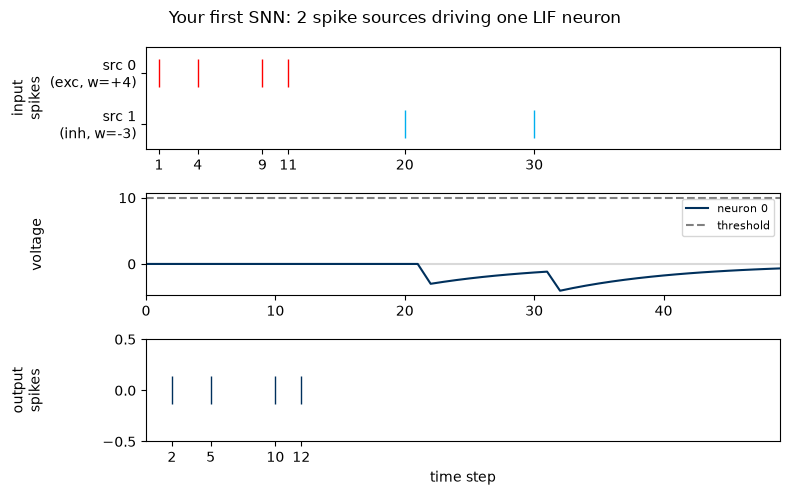

In [7]:
spike_times = pop1.get_spikes()
voltages = pop1.get_voltages()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 5))

# input spikes — separate the two sources by their effect on the LIF neuron
ax1.plot(input_spikes[0], [1] * len(input_spikes[0]), "|", ms=20, c="red", label="excitatory")
ax1.plot(input_spikes[1], [0] * len(input_spikes[1]), "|", ms=20, c="#00afef", label="inhibitory")
ax1.set_xticks(input_spikes[0] + input_spikes[1])
ax1.set_xlim(0, timesteps - 1)
ax1.set_ylabel("input\nspikes")
ax1.set_ylim(-0.5, stim.size - 0.5)
ax1.set_yticks([0, 1])
ax1.set_yticklabels(["src 1\n(inh, w=-3)", "src 0\n(exc, w=+4)"])

# membrane voltage
ax2.plot(np.arange(timesteps), voltages[0], color="#00305C", label="neuron 0")
ax2.axhline(params["threshold"], ls="--", c="0.5", label="threshold")
ax2.axhline(0, ls="-", c="0.85", zorder=0)
ax2.set_xlim(0, timesteps - 1)
ax2.set_ylabel("voltage")
ax2.legend(loc="upper right", fontsize=8)

# output spikes
idx, timestep = helpers.spike_times_dict_to_arrays(spike_times)
ax3.plot(timestep, idx, "|", ms=20, color="#00305C")
ax3.set_ylabel("output\nspikes")
ax3.set_ylim(-0.5, pop1.size - 0.5)
ax3.set_xlabel("time step")
ax3.set_xticks(timestep)
ax3.set_xlim(0, timesteps - 1)

fig.suptitle("Your first SNN: 2 spike sources driving one LIF neuron")
fig.align_ylabels()  # line up the three y-axis labels
plt.tight_layout()
plt.show()

**What to notice:**

- Each input spike from source 0 nudges the voltage **up** (excitatory, +4); it then
  leaks back down between spikes.

- When the voltage crosses the dashed threshold line, the neuron emits an **output
  spike** (bottom panel) and the voltage drops by the threshold amount
  (`reset="reset_by_subtraction"`).

- Source 1's spikes at t=20 and t=30 are **inhibitory** (−3): watch the voltage dip and then recover toward the resting potential `v_rest=0`.

- The voltage trace may look like it never reaches the threshold. That's because integration and reset happen in the same time step — the neuron does cross the threshold, but the reset drops it back down before the value is recorded. The crossing shows up in the output spikes, just not in the voltage curve.


> **Tip**
>
> 👉 **Try it yourself:** lower `threshold` to 6, or raise the excitatory weight to 8,
> and re-run. How does the output spike train change?

## 6. Now something flashy: a synfire chain

A **synfire chain** is a classic neuromorphic showcase. Groups of neurons are wired
feed-forward — group 0 drives group 1, group 1 drives group 2, and so on — with
balancing inhibition *within* each group.

Each group has excitatory neurons that *push* the next neurons to fire and inhibitory neurons that *push back*. The moment a group fires, its own inhibition damps it — so the volley stays sharp (neurons fire once, together) and stable (the excitation can't die out or blow up into runaway activity). A short, sharp burst of input to the first
group triggers a tight **volley** of synchronized spikes that propagates cleanly from
group to group, like a wave.

> **Note**
>
> This network is composed of **1,250 neurons** (plus 200 input sources) wired by **100,000 synapses**. It takes less than a second to simulate it on the Brian2 backend, and on SpiNNaker2, it runs in **real time** — 80 time steps at 1 ms each, so 0.08 s. The tuned parameters below come straight from the repo's `examples/synfire_chain/`.

### 6.1 Network parameters

The chain is **5 groups** of 250 neurons each (200 excitatory + 50 inhibitory). The weights, delays, connectivity, and neuron-model parameters below are tuned values taken from the repo's `examples/synfire_chain/`.

In [8]:
n_groups = 5
n_exc, n_inh = 200, 50  # excitatory / inhibitory neurons per group
n_pop = n_exc + n_inh

w_exc, delay_exc = 15.0, 7  # excitatory weight & delay
w_inh, delay_inh = -2.14, 5  # inhibitory weight & delay
n_pre_conn_exc = 60  # excitatory inputs each neuron receives
n_pre_conn_inh = 25  # inhibitory inputs each neuron receives

# Tuned LIF (current-based) parameters
params = {
    "threshold": 1167.67,
    "alpha_decay": 0.904837,
    "i_offset": 0.0,
    "v_reset": 0.0,
    "exc_decay": 0.513417119,
    "inh_decay": 0.36787944,
    "t_refract": 2,
    "reset": "reset_to_v_reset",
}

### 6.2 The kick: input to the first group

We start the chain with a short, sharp burst — each of the `n_exc` input sources fires once around time step 25 (with a little jitter from a normal distribution).

In [9]:
rng = np.random.default_rng(seed=1)  # fixed seed -> reproducible wave

kick = rng.normal(25, 2, n_exc).astype(int)  # one spike time per source, around time step 25
input_spikes = {i: [int(timestep)] for i, timestep in enumerate(kick)}
stim = snn.Population(
    size=n_exc,
    neuron_model="spike_list",
    params=input_spikes,
    name="kick",
)

### 6.3 One population per group

Five groups of [`lif_curr_exp`](https://spinnaker2.gitlab.io/py-spinnaker2/api_reference/neuron-models.html#leaky-integratefire-neuron-with-exponentially-decaying-current-input-lif_curr_exp) neurons — a different model from the `lif` above. The difference is how an incoming spike reaches the membrane voltage:

- **`lif`**: a spike is added *straight to the voltage* — a one-step kick, up (excitatory) or down (inhibitory).
- **`lif_curr_exp`** is *current-based*: a spike instead feeds a synaptic **current** that decays exponentially over several steps (separate excitatory and inhibitory channels, `exc_decay` / `inh_decay`), and that current drives the voltage. In addition, neurons of this model have a refractory period (`t_refract`) after firing.

These smooth, decaying currents are what shape the sharp, balanced volleys a synfire chain needs. (More on neuron models in [01 · Core concepts](./01_core_concepts.ipynb).)

We record `spikes` and the voltage `v` so we can animate the wave afterwards.

In [10]:
pops = []
for i in range(n_groups):
    pop = snn.Population(
        size=n_pop,
        neuron_model="lif_curr_exp",
        params=params,
        name=f"group_{i}",
        record=["spikes", "v"],
    )
    pop.set_max_atoms_per_core(100)  # hardware mapping hint (ignored by Brian2); >100 exceeds PE memory here
    pops.append(pop)

### 6.4 Assemble the network

Add the kick and all five groups to one `Network`.

In [11]:
snn.Network.clear_names()  # allow re-running this cell (until SpiNNcloud's fix lands)
net = snn.Network("synfire_chain")
net.add(stim, *pops)

### 6.5 Feed-forward excitation

Each group drives the next: kick → group 0 → group 1 → … → group 4. Every post neuron receives `n_pre_conn_exc` connections from randomly chosen pre neurons.

In [12]:
pre_pops = [stim] + pops[:-1]  # what drives each group: the kick, then groups 0..3
for pre, post in zip(pre_pops, pops):
    conns = []
    for post_id in range(post.size):
        for pre_id in rng.permutation(pre.size)[:n_pre_conn_exc]:
            conns.append([int(pre_id), post_id, w_exc, delay_exc])
    net.add(snn.Projection(pre=pre, post=post, connections=conns))

### 6.6 Local inhibition

Within each group, the inhibitory neurons (indices `n_exc`…`n_pop`) connect back onto the excitatory ones (indices `0`…`n_exc`). This is the *balancing inhibition* that keeps each volley sharp.

In [13]:
inh_ids = np.arange(n_exc, n_pop)  # the inhibitory neurons within a group
for pop in pops:
    conns = []
    for post_id in range(n_exc):
        for pre_id in rng.permutation(inh_ids)[:n_pre_conn_inh]:
            conns.append([int(pre_id), post_id, w_inh, delay_inh])
    net.add(snn.Projection(pre=pop, post=pop, connections=conns))

### 6.7 Run the network

Same `hw.run` as the first example, for 80 time steps.

In [14]:
if USE_HARDWARE:
    # A Hardware object allows only one run() — create a fresh one for this second experiment.
    hw = hardware.SpiNNcloud48NodeBoard()

n_synapses = sum(p.sparse_weights.nnz for p in net.projections)
print(f"Network built: {n_groups} groups, {n_synapses} synapses")

timesteps = 80
hw.run(net, timesteps)

Network built: 5 groups, 100000 synapses


Number of cores needed: 16
Number of available cores: 7104
Sim duration: 0.09 s


Recording post-processing duration: 0 s


### 6.8 Visualize the results

In [15]:
# Shared imports for the two animations below.
from pathlib import Path
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from IPython.display import HTML

### 6.9 The wave, neuron by neuron

We lay **every neuron in one continuous row** — group 0 on the left through group 4 on the right, no gaps — and colour each by its membrane voltage (dark = near zero, bright orange/yellow = near the firing threshold). Each group lights up a few time steps after the one to its left, so a bright band flows **left → right** across the row: the wave.

In [16]:
# voltages of all neurons, ordered group 0 -> group 4  ->  shape (N, T)
allv = np.concatenate([np.array([pop.get_voltages()[j] for j in range(pop.size)]) for pop in pops], axis=0)
N, T = allv.shape

fig, ax = plt.subplots(figsize=(10, 2.6))
im = ax.imshow(allv[:, 0][None, :], aspect="auto", cmap="inferno", vmin=0, vmax=params["threshold"])
ax.set_yticks([])
ax.set_xticks([(i + 0.5) * n_pop for i in range(n_groups)])
ax.set_xticklabels([f"group {i}" for i in range(n_groups)])
fig.colorbar(im, ax=ax, label="membrane voltage")


def update(timestep):
    im.set_data(allv[:, timestep][None, :])
    ax.set_title(f"Membrane voltage of every neuron — timestep {timestep:>2}")
    return (im,)


anim = animation.FuncAnimation(fig, update, frames=T, interval=100, blit=False)
plt.close(fig)

gif_path = Path("images/synfire_voltage_wave.gif")
gif_path.parent.mkdir(exist_ok=True)
anim.save(gif_path, writer=PillowWriter(fps=10), dpi=80)
HTML(f'<img src="{gif_path}" alt="animation">')

**What you're seeing:**

- **Group 0 looks striped, not a solid block.** It's driven by the *kick*, whose spike times are jittered (a normal distribution around time step 25). Each neuron gets a random subset of those jittered inputs, so neighbours charge at slightly different rates and cross threshold at slightly different moments — at any frame they sit at different voltages, which reads as vertical stripes.
- **The later groups get cleaner, and the last is a solid orange block.** A synfire chain *sharpens* the volley as it travels: each group fires a tight, synchronized pulse that drives the next even more synchronously. By group 4 the neurons charge in near-perfect lockstep, so they all reach the same voltage on the same frame — one uniform orange band, no stripes.

### 6.10 The wave, as a smooth profile

As an extra view: collapse each group to its **mean voltage**, place the groups along a line, and smooth the five values into one continuous profile. The same volley now shows up as a single wave **gliding from group 0 to group 4**.

In [17]:
# mean voltage of each group's excitatory neurons over time -> shape (n_groups, T)
group_v = np.array([np.mean([pop.get_voltages()[j] for j in range(n_exc)], axis=0) for pop in pops])
T = group_v.shape[1]

x = np.linspace(0, n_groups - 1, 400)  # continuous position along the chain
sigma = 0.5  # how far each group bleeds into its neighbours


def wave(timestep):
    # a Gaussian bump at each group position, weighted by that group's activity, summed
    return sum(group_v[g, timestep] * np.exp(-((x - g) ** 2) / (2 * sigma**2)) for g in range(n_groups))


fig, ax = plt.subplots(figsize=(9, 4))
ax.set_xlim(0, n_groups - 1)
ax.set_ylim(0, group_v.max() * 1.1)
ax.set_xticks(range(n_groups))
ax.set_xticklabels([f"group {i}" for i in range(n_groups)])
ax.set_ylabel("mean membrane voltage")
(line,) = ax.plot(x, wave(0), color="deepskyblue", lw=2)


def update(timestep):
    y = wave(timestep)
    line.set_ydata(y)
    for coll in list(ax.collections):  # refresh the filled area
        coll.remove()
    ax.fill_between(x, y, color="deepskyblue", alpha=0.3)
    ax.set_title(f"Mean voltage along the chain — timestep {timestep:>2}")
    return (line,)


anim = animation.FuncAnimation(fig, update, frames=T, interval=100, blit=False)
plt.close(fig)

gif_path = Path("images/synfire_wave_profile.gif")
gif_path.parent.mkdir(exist_ok=True)
anim.save(gif_path, writer=PillowWriter(fps=10), dpi=80)
HTML(f'<img src="{gif_path}" alt="animation">')

## Recap & what's next

You just:

- learned the four building blocks — **Population → Projection → Network → backend**,
- ran a single LIF neuron and read back its spikes and voltage,
- propagated a synchronized volley through a 5-group synfire chain,
- all through **one backend switch** that works for both software and hardware.

**Next up — [01 · Core concepts](./01_core_concepts.ipynb):** we slow down and explore
populations, the available neuron models, and how parameters (population-wide *and*
per-neuron) shape behavior.

> **Note**
>
> 🧭 Stuck on something? [05 · Debugging & reading the output](./05_debugging.ipynb) is a dedicated debugging guide — common errors, how to turn on debug logs, and how to read what the hardware is doing.